In [ ]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install py3Dmol
      !pip install rdkit
      pbar.update(50)
      from rdkit import Chem
      from rdkit.Chem import Draw
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import AllChem # import the AllChem submodule from the Chem module
      from rdkit.Chem import rdDistGeom
      from rdkit.Chem import rdDepictor
      from rdkit.Chem import rdFMCS as MCS # Importar rdFMCS como MCS, siguiendo la recomendación de deprecación
      from IPython.display import Image
      import py3Dmol


      pbar.update(50)

In [ ]:
ps = rdDistGeom.ETKDGv3()
ps.clearConfs= False


In [16]:
oseltamivir = Chem.MolFromSmiles('CCC(CC)OC1C=C(C(=O)OCC)C(NC(=O)C)C(N)C1')
oseltamivir_H = Chem.AddHs(oseltamivir)
oseltamivir_embed = AllChem.EmbedMolecule(oseltamivir_H)
cid = rdDistGeom.EmbedMolecule(oseltamivir_H,ps)

In [17]:
zanamivir = Chem.MolFromSmiles('CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](CO)O)O)C(=O)O)N=C(N)N')
mol2 = Chem.AddHs(zanamivir)
AllChem.EmbedMolecule(mol2)
cid = rdDistGeom.EmbedMolecule(mol2,ps)

In [18]:
lanimavir = Chem.MolFromSmiles("CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](COC)O)O)C(=O)O)N=C(N)N")
mol3 = Chem.AddHs(lanimavir)
AllChem.EmbedMolecule(mol3)
cid = rdDistGeom.EmbedMolecule(mol3,ps)

In [19]:
peramivir = Chem.MolFromSmiles('CCC(CC)[C@@H](NC(=O)C)[C@H]1[C@@H](C(=O)O)[C@H](N=C(N)N)[C@@H](O)C1')
mol4 = Chem.AddHs(peramivir)
AllChem.EmbedMolecule(mol4)
cid = rdDistGeom.EmbedMolecule(mol4,ps)


In [20]:
a315375 = Chem.MolFromSmiles('CCC(CC)[C@H]1N(C(=O)C)[C@@H](C=C1C(=O)O)C2CCCCC2')
mol5 = Chem.AddHs(a315375)
AllChem.EmbedMolecule(mol5)
cid = rdDistGeom.EmbedMolecule(mol5,ps)

### Alinear múltiples moléculas a una referencia común

Dado que `AlignMol` alinea una molécula ('probe') a otra ('reference'), para alinear múltiples moléculas, podemos seleccionar una como referencia y alinear todas las demás a esa referencia. Luego, visualizamos todas las moléculas alineadas en la misma vista.

In [22]:
# from rdkit.Chem import Draw
# from rdkit.Chem import Chem # Este import es redundante y causa el error

# El 'mcs_mol_2d' fue calculado en la celda '8bbccfe2' como el MCS entre oseltamivir y zanamivir (2D).
# Lo usaremos como la subestructura común para resaltar en todas las moléculas 2D.
mols_to_align = [
    ("oseltamivir (Referencia)", oseltamivir_H, 'greenCarbon'), # Referencia
    ("zanamivir", mol2, 'pinkCarbon'),
     ("lanimavir", mol3, 'blueCarbon'),
     ("peramivir", mol4, 'orangeCarbon'),
     ("a315375", mol5, 'purpleCarbon')
    ]
# Lista de moléculas 2D base para la visualización
all_molecules_2d_with_names = [
    ("oseltamivir", oseltamivir),
    ("zanamivir", zanamivir),
    ("lanimavir", lanimavir),
     ("peramivir", peramivir),
     ("a315375", a315375)
]

In [23]:
molecules_for_mcs = [mol for name, mol in all_molecules_2d_with_names]

mcs_result_2d = MCS.FindMCS(molecules_for_mcs)
mcs_mol_2d = Chem.MolFromSmarts(mcs_result_2d.smartsString)



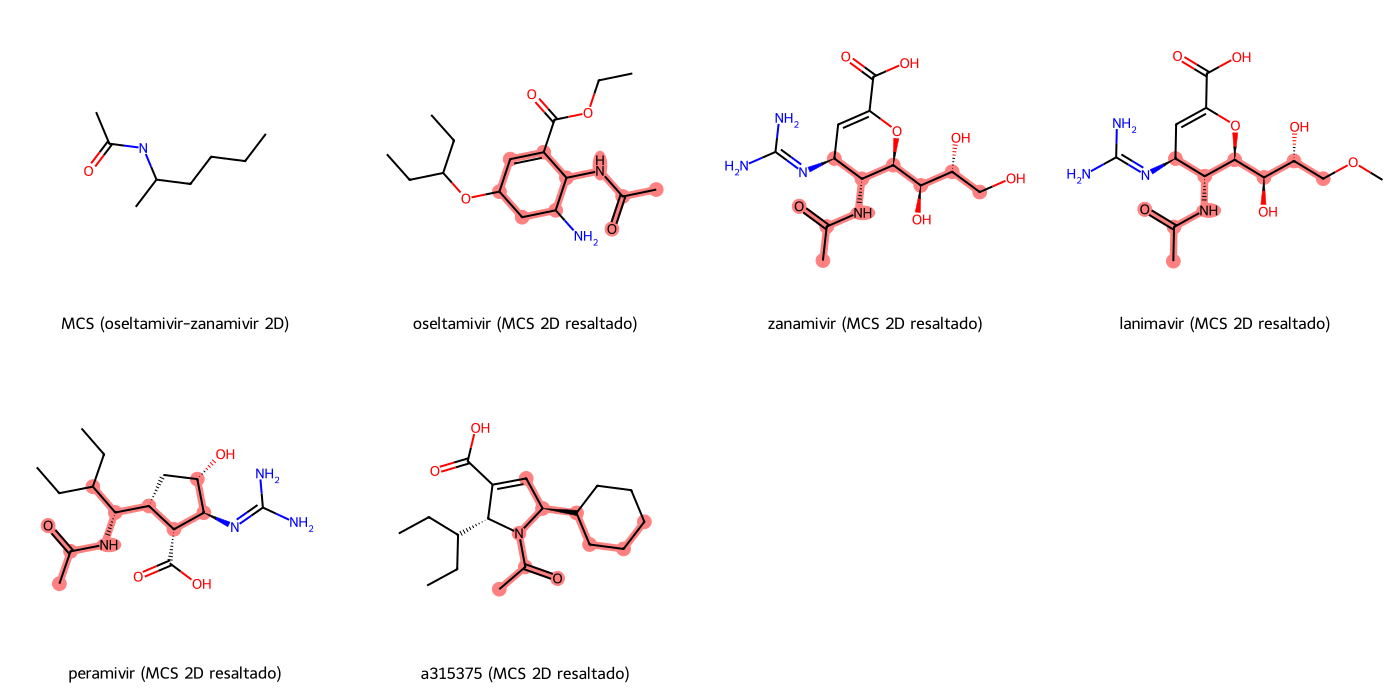

In [24]:


mols_for_grid_display_2d = []
legends_for_grid_display_2d = []
highlight_atom_lists_display_2d = []

# 1. Añadir el MCS común (2D) a la cuadrícula
mols_for_grid_display_2d.append(mcs_mol_2d)
legends_for_grid_display_2d.append("MCS (oseltamivir-zanamivir 2D)")
highlight_atom_lists_display_2d.append([]) # No se resaltan átomos en el MCS en sí

# 2. Iterar sobre las moléculas 2D y preparar para la visualización con resaltado del MCS
for name, current_mol_2d in all_molecules_2d_with_names:
    # Encontrar las coincidencias del MCS_2D dentro de la molécula actual
    matches = current_mol_2d.GetSubstructMatches(mcs_mol_2d)

    highlight_atoms = []
    if matches:
        # Usar la primera coincidencia para el resaltado
        highlight_atoms = list(matches[0])

    mols_for_grid_display_2d.append(current_mol_2d)
    legends_for_grid_display_2d.append(f"{name} (MCS 2D resaltado)")
    highlight_atom_lists_display_2d.append(highlight_atoms)

# 3. Generar la imagen en cuadrícula
grid_image_2d_final = Draw.MolsToGridImage(mols_for_grid_display_2d,
                                          subImgSize=(350,350),
                                          molsPerRow=4, # Se ajusta a 3 para un mejor diseño visual
                                          legends=legends_for_grid_display_2d,
                                          highlightAtomLists=highlight_atom_lists_display_2d,
                                          maxMols=len(mols_for_grid_display_2d))

# 4. Mostrar la imagen
grid_image_2d_final

In [26]:

# La primera molécula en la lista será nuestra referencia
reference_mol_name, reference_mol, reference_color = mols_to_align[0]

v_multi = py3Dmol.view(width=600, height=400)
v_multi.removeAllModels()

# Añadir la molécula de referencia a la vista
IPythonConsole.addMolToView(reference_mol, v_multi, confId=-1)

print(f"Alineando moléculas a: {reference_mol_name}")

# Iterar sobre el resto de las moléculas y alinearlas a la referencia
for i, (name, probe_mol, color) in enumerate(mols_to_align[1:]):
    # Encontrar la Subestructura Común Máxima (MCS) entre la molécula probe y la referencia
    mcs_result = MCS.FindMCS([probe_mol, reference_mol])

    if mcs_result.numAtoms > 0:
        mcs_mol = Chem.MolFromSmarts(mcs_result.smartsString)

        # Obtener los mapeos de átomos para el MCS en ambas moléculas
        matches_probe = probe_mol.GetSubstructMatches(mcs_mol)
        matches_ref = reference_mol.GetSubstructMatches(mcs_mol)

        if matches_probe and matches_ref:
            # Usar la primera coincidencia para construir el atomMap
            match_probe_indices = matches_probe[0]
            match_ref_indices = matches_ref[0]

            # Construir el atomMap: lista de pares (indice_atomo_mol_probe, indice_atomo_mol_referencia)
            atomMap = [(match_probe_indices[k], match_ref_indices[k]) for k in range(len(match_probe_indices))]

            # Alinear la molécula probe a la referencia usando el atomMap
            rmsd = AllChem.AlignMol(probe_mol, reference_mol, atomMap=atomMap)

            # Añadir la molécula alineada a la vista. El índice del modelo será i+1 ya que la referencia es 0.
            IPythonConsole.addMolToView(probe_mol, v_multi, confId=-1)
            v_multi.setStyle({}, {})
            # Imprimir el RMSD
            print(f"RMSD de {name} con respecto a {reference_mol_name}: {rmsd:.2f}")
        else:
            print(f"Advertencia: No se pudo encontrar una coincidencia de subestructura del MCS para {name}.")
    else:
        print(f"Advertencia: No se encontró una Subestructura Común Máxima entre {name} y {reference_mol_name}.")

# Establecer los estilos para cada molécula
v_multi.setStyle({'model': 0}, {'stick': {'colorscheme': reference_color}})
for i, (_, _, color) in enumerate(mols_to_align[1:]):
    v_multi.addStyle({'model': i + 1}, {'line': {'colorscheme': color}})

v_multi.zoomTo()
v_multi.show()

Alineando moléculas a: oseltamivir (Referencia)
RMSD de zanamivir con respecto a oseltamivir (Referencia): 1.94
RMSD de lanimavir con respecto a oseltamivir (Referencia): 2.01
RMSD de peramivir con respecto a oseltamivir (Referencia): 1.55
RMSD de a315375 con respecto a oseltamivir (Referencia): 2.12


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

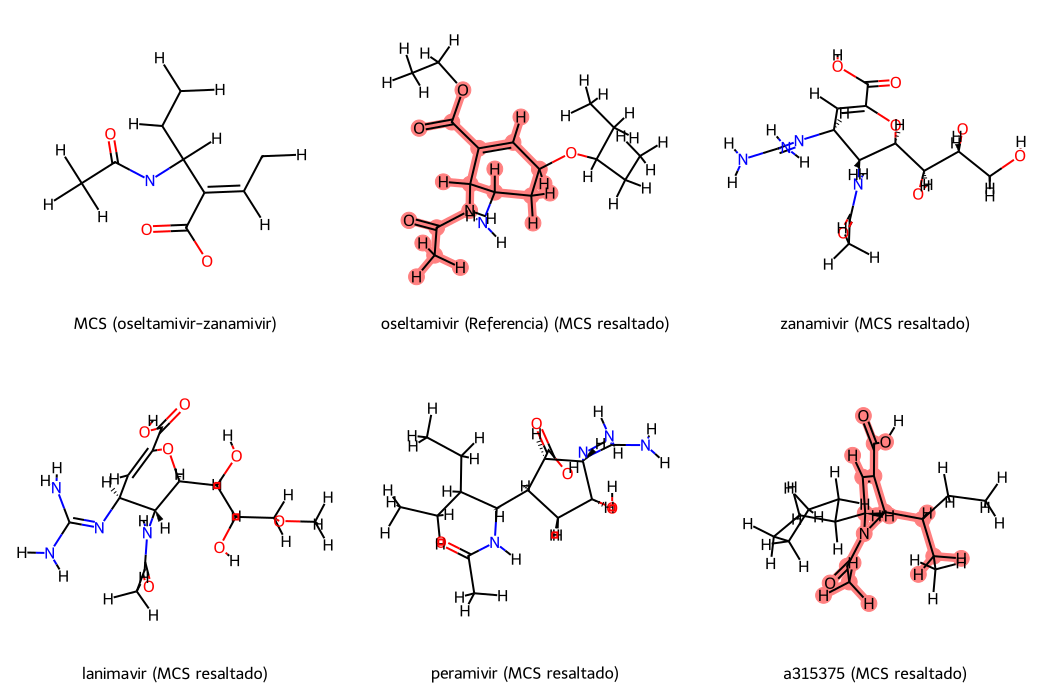

In [28]:
# from rdkit.Chem import rdFMCS as MCS # Asegurarse de que MCS esté importado

# Reutilizar el MCS encontrado previamente entre oseltamivir y zanamivir
# Este 'mcs_mol' es la subestructura común entre oseltamivir y zanamivir (mol2).
# Asumiremos que es la 'estructura común' que se desea resaltar en todas las moléculas.
common_mcs_mol = mcs_mol

mols_for_grid_display = []
legends_for_grid_display = []
highlight_atom_lists_display = []

# 1. Añadir la molécula del MCS común en sí misma a la cuadrícula
mols_for_grid_display.append(common_mcs_mol)
legends_for_grid_display.append("MCS (oseltamivir-zanamivir)")
highlight_atom_lists_display.append([]) # No se resaltan átomos en el MCS en sí

# 2. Iterar sobre las moléculas alineadas y preparar para la visualización con resaltado
# Usamos las moléculas que ya fueron alineadas (modificadas in-place por AllChem.AlignMol)
all_molecules_with_names = [
    ("oseltamivir (Referencia)", oseltamivir_H),
    ("zanamivir", mol2),
    ("lanimavir", mol3),
    ("peramivir", mol4),
    ("a315375", mol5)
 ]

for name, current_mol in all_molecules_with_names:
    # Encontrar las coincidencias de la subestructura común (common_mcs_mol) dentro de la molécula actual
    matches = current_mol.GetSubstructMatches(common_mcs_mol)

    highlight_atoms = []
    if matches:
        highlight_atoms = list(matches[0]) # Usar la primera coincidencia para el resaltado

    mols_for_grid_display.append(current_mol) # Añadir la molécula (ya alineada)
    legends_for_grid_display.append(f"{name} (MCS resaltado)")
    highlight_atom_lists_display.append(highlight_atoms)

# 3. Generar la imagen en cuadrícula
# El número de filas por columna se ajusta a 3 para un mejor diseño visual (5 elementos en total)
grid_image_final = Draw.MolsToGridImage(mols_for_grid_display,
                                        subImgSize=(350,350),
                                        molsPerRow=3,
                                        legends=legends_for_grid_display,
                                        highlightAtomLists=highlight_atom_lists_display,
                                        maxMols=len(mols_for_grid_display))

# 4. Mostrar la imagen
grid_image_final

In [13]:
# 1. Instalación de dependencias (Ejecutar en Colab)
!pip install -q rdkit pandas py3Dmol

import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, rdDistGeom

# 2. Definición del dataset completo de moléculas
oseltamivir_data = {
    "Nombre": [
        "Oseltamivir (Profármaco)",
        "Oseltamivir Carboxilato (Metabolito Activo)",
        "Análogo N-Propionilo",
        "Derivado Ciclopentil éter",
        "Derivado Amida (Éster a Metilamida)",
        "Análogo Guanidino (Estilo Zanamivir)",
        "DANA (Neu5Ac2en - Prototipo)",
        "Zanamivir (Relenza)",
        "Laninamivir (Inavir - Forma activa)",
        "Octanoato de Laninamivir (Profármaco CS-8958)",
        "Peramivir (Rapivab - Núcleo Ciclopentano)",
        "A-315675 (Inhibidor Pirrolidínico)"
    ],
    "SMILES": [
        "CCC(CC)OC1C=C(C(=O)OCC)C(NC(=O)C)C(N)C1",        # Oseltamivir
        "CCC(CC)OC1C=C(C(=O)O)C(NC(=O)C)C(N)C1",          # Carboxilato
        "CCC(CC)OC1C=C(C(=O)OCC)C(NC(=O)CC)C(N)C1",       # N-propionilo
        "C1CCC(CC1)OC2C=C(C(=O)OCC)C(NC(=O)C)C(N)C2",      # Ciclopentil
        "CCC(CC)OC1C=C(C(=O)NC)C(NC(=O)C)C(N)C1",         # Metilamida
        "CCC(CC)OC1C=C(C(=O)O)C(NC(=O)C)C(NC(=N)N)C1",     # Guanidino
        "CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](CO)O)O)C(=O)O)O",                             # DANA
        "CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](CO)O)O)C(=O)O)N=C(N)N",                       # Zanamivir
        "CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](COC)O)O)C(=O)O)N=C(N)N",                       # Laninamivir
        "CCCCCCCC(=O)O[C@H](COC)[C@@H](O)[C@@H]1OC(=CC(N=C(N)N)[C@H]1NC(C)=O)C(=O)O",             # Laninamivir Octanoato
        "CCC(CC)[C@@H](NC(=O)C)[C@H]1[C@@H](C(=O)O)[C@H](N=C(N)N)[C@@H](O)C1",                      # Peramivir
        "CCC(CC)[C@H]1N(C(=O)C)[C@@H](C=C1C(=O)O)C2CCCCC2"                                        # A-315675
    ]
}

# 3. Configuración de parámetros de incrustación 3D (ETKDGv3)
ps = rdDistGeom.ETKDGv3()
ps.randomSeed = 42  # Para reproducibilidad

resultados = []
moleculas_3d_dict = {}

# 4. Bucle aplicando el algoritmo a cada molécula
for nombre, smiles in zip(oseltamivir_data["Nombre"], oseltamivir_data["SMILES"]):
    mol = Chem.MolFromSmiles(smiles)

    if mol is not None:
        # Añadir hidrógenos explícitos
        mol2 = Chem.AddHs(mol)

        # Generar conformación 3D (Incrustación por geometría de distancias)
        cid = rdDistGeom.EmbedMolecule(mol2, ps)

        # Optimización de energía con campo de fuerza MMFF94
        opt_status = AllChem.MMFFOptimizeMolecule(mol2)

        # Guardar en diccionario para posterior exportación o visualización
        moleculas_3d_dict[nombre] = mol2

        resultados.append({
            "Molécula": nombre,
            "Átomos Totales (+H)": mol2.GetNumAtoms(),
            "Conformer ID (cid)": cid,
            "Incrustación 3D": "Éxito (cid=0)" if cid == 0 else "Fallida",
            "Optimizado MMFF94": "Sí" if opt_status == 0 else "Parcial"
        })

# 5. Mostrar tabla de resultados en Colab
df_resultados = pd.DataFrame(resultados)
display(df_resultados)

# 6. Guardar todas las estructuras 3D generadas en un archivo .SDF
writer = Chem.SDWriter("oseltamivir_y_analogos_3D.sdf")
for nombre, mol_3d in moleculas_3d_dict.items():
    mol_3d.SetProp("_Name", nombre)
    writer.write(mol_3d)
writer.close()

print("\nSe ha generado con éxito el archivo 'oseltamivir_y_analogos_3D.sdf' con las estructuras 3D optimizadas.")

,Molécula,Átomos Totales (+H),Conformer ID (cid),Incrustación 3D,Optimizado MMFF94
0,Oseltamivir (Profármaco),50,0,Éxito (cid=0),Parcial
1,Oseltamivir Carboxilato (Metabolito Activo),44,0,Éxito (cid=0),Parcial
2,Análogo N-Propionilo,53,0,Éxito (cid=0),Parcial
3,Derivado Ciclopentil éter,51,0,Éxito (cid=0),Parcial
4,Derivado Amida (Éster a Metilamida),48,0,Éxito (cid=0),Parcial
5,Análogo Guanidino (Estilo Zanamivir),49,0,Éxito (cid=0),Parcial
6,DANA (Neu5Ac2en - Prototipo),37,0,Éxito (cid=0),Parcial
7,Zanamivir (Relenza),43,0,Éxito (cid=0),Sí
8,Laninamivir (Inavir - Forma activa),46,0,Éxito (cid=0),Parcial
9,Octanoato de Laninamivir (Profármaco CS-8958),69,0,Éxito (cid=0),Parcial



Se ha generado con éxito el archivo 'oseltamivir_y_analogos_3D.sdf' con las estructuras 3D optimizadas.


Traceback (most recent call last):
  File "/usr/local/bin/pip3", line 4, in <module>
    from pip._internal.cli.main import main
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/main.py", line 11, in <module>
    from pip._internal.cli.autocompletion import autocomplete
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/autocompletion.py", line 10, in <module>
    from pip._internal.cli.main_parser import create_main_parser
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/main_parser.py", line 9, in <module>
    from pip._internal.build_env import get_runnable_pip
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/build_env.py", line 19, in <module>
    from pip._internal.cli.spinners import open_spinner
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/spinners.py", line 9, in <module>
    from pip._internal.utils.logging import get_indentation
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/util

,Nombre,SMILES,MW (g/mol),LogP,HBD,HBA,TPSA (Å²),Lipinski
0,Oseltamivir (Profármaco),CCC(CC)OC1C=C(C(=O)OCC)C(NC(=O)C)C(N)C1,312.41,1.29,2,5,90.65,Cumple
1,Oseltamivir Carboxilato (Metabolito Activo),CCC(CC)OC1C=C(C(=O)O)C(NC(=O)C)C(N)C1,284.36,0.81,3,4,101.65,Cumple
2,Análogo N-Propionilo,CCC(CC)OC1C=C(C(=O)OCC)C(NC(=O)CC)C(N)C1,326.44,1.68,2,5,90.65,Cumple
3,Derivado Ciclopentil éter,C1CCC(CC1)OC2C=C(C(=O)OCC)C(NC(=O)C)C(N)C2,324.42,1.43,2,5,90.65,Cumple
4,Derivado Amida (Éster a Metilamida),CCC(CC)OC1C=C(C(=O)NC)C(NC(=O)C)C(N)C1,297.40,0.47,3,4,93.45,Cumple
5,Análogo Guanidino (Estilo Zanamivir),CCC(CC)OC1C=C(C(=O)O)C(NC(=O)C)C(NC(=N)N)C1,326.40,0.33,5,4,137.53,Cumple
6,DANA (Neu5Ac2en - Prototipo),CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](C...,291.26,-3.07,6,7,156.55,No cumple
7,Zanamivir (Relenza),CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](C...,332.31,-3.79,7,7,200.72,No cumple
8,Laninamivir (Inavir - Forma activa),CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](C...,346.34,-3.13,6,7,189.72,No cumple
9,Octanoato de Laninamivir (Profármaco CS-8958),CCCCCCCC(=O)O[C@H](COC)[C@@H](O)[C@@H]1OC(=CC(...,472.54,-0.22,5,8,195.79,Cumple


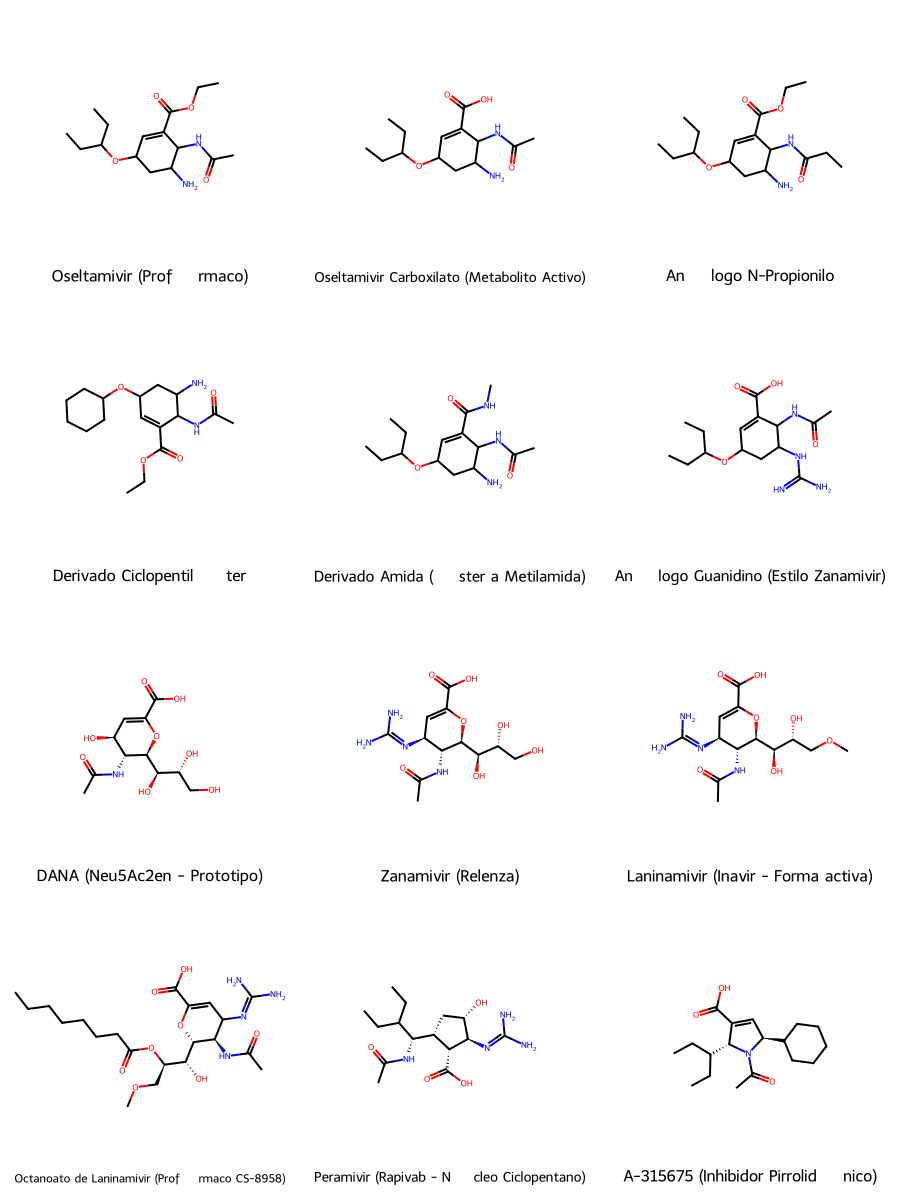

In [14]:
# 1. Instalación de dependencias
!pip install -q rdkit pandas matplotlib

import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, Lipinski

# 2. Definición del Oseltamivir y análogos/derivados representativos
oseltamivir_data = {
    "Nombre": [
        "Oseltamivir (Profármaco)",
        "Oseltamivir Carboxilato (Metabolito Activo)",
        "Análogo N-Propionilo",
        "Derivado Ciclopentil éter",
        "Derivado Amida (Éster a Metilamida)",
        "Análogo Guanidino (Estilo Zanamivir)",
         "DANA (Neu5Ac2en - Prototipo)",
        "Zanamivir (Relenza)",
        "Laninamivir (Inavir - Forma activa)",
        "Octanoato de Laninamivir (Profármaco CS-8958)",
        "Peramivir (Rapivab - Núcleo Ciclopentano)",
        "A-315675 (Inhibidor Pirrolidínico)"
    ],
    "SMILES": [
        "CCC(CC)OC1C=C(C(=O)OCC)C(NC(=O)C)C(N)C1",        # Oseltamivir
        "CCC(CC)OC1C=C(C(=O)O)C(NC(=O)C)C(N)C1",          # Carboxilato
        "CCC(CC)OC1C=C(C(=O)OCC)C(NC(=O)CC)C(N)C1",       # N-propionilo
        "C1CCC(CC1)OC2C=C(C(=O)OCC)C(NC(=O)C)C(N)C2",      # Ciclopentil
        "CCC(CC)OC1C=C(C(=O)NC)C(NC(=O)C)C(N)C1",         # Metilamida
        "CCC(CC)OC1C=C(C(=O)O)C(NC(=O)C)C(NC(=N)N)C1",     # Guanidino
        "CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](CO)O)O)C(=O)O)O",                             # DANA
        "CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](CO)O)O)C(=O)O)N=C(N)N",                       # Zanamivir
        "CC(=O)N[C@@H]1[C@H](C=C(O[C@H]1[C@@H]([C@@H](COC)O)O)C(=O)O)N=C(N)N",                       # Laninamivir
        "CCCCCCCC(=O)O[C@H](COC)[C@@H](O)[C@@H]1OC(=CC(N=C(N)N)[C@H]1NC(C)=O)C(=O)O",             # Laninamivir Octanoato
        "CCC(CC)[C@@H](NC(=O)C)[C@H]1[C@@H](C(=O)O)[C@H](N=C(N)N)[C@@H](O)C1",                      # Peramivir
        "CCC(CC)[C@H]1N(C(=O)C)[C@@H](C=C1C(=O)O)C2CCCCC2"
    ]
}

df = pd.DataFrame(oseltamivir_data)

# 3. Función para calcular propiedades fisicoquímicas y Lipinski
def calcular_propiedades(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if not mol:
        return None
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)
    tpsa = Descriptors.TPSA(mol)

    # Regla de Lipinski (Ro5)
    lipinski_pass = (mw <= 500) and (logp <= 5) and (hbd <= 5) and (hba <= 10)

    return {
        "MW (g/mol)": round(mw, 2),
        "LogP": round(logp, 2),
        "HBD": hbd,
        "HBA": hba,
        "TPSA (Å²)": round(tpsa, 2),
        "Lipinski": "Cumple" if lipinski_pass else "No cumple"
    }

# 4. Procesamiento e integración de datos
propiedades = [calcular_propiedades(s) for s in df["SMILES"]]
df_resultado = pd.concat([df, pd.DataFrame(propiedades)], axis=1)

# Mostrar tabla en Colab
display(df_resultado)

# 5. Visualización 2D de las estructuras
mols = [Chem.MolFromSmiles(s) for s in df["SMILES"]]
img = Draw.MolsToGridImage(mols, legends=list(df["Nombre"]), molsPerRow=3, subImgSize=(300, 300))
img

Para complementar Enalapril (conversión prodroga/estereocentros) y Oseltamivir (resistencia por mutación conformacional), lo ideal es estudiar casos centrados en flexibilidad conformacional de cinasas, bioisosterismo estricto o selectividad por subbolsillos.

1. Inhibidores de Cinasas (BCR-Abl): Imatinib vs. Dasatinib

Mecanismo: Inhibición Tipo I vs. Tipo II.

Interés molecular: Imatinib se une a la conformación inactiva (DFG-out) del dominio cinasa, mientras que Dasatinib reconoce la conformación activa (DFG-in). Alinearlos muestra cómo dos fármacos dirigidos a la misma proteína ocupan geometrías tridimensionales completamente disímiles en el sitio de unión al ATP.

2. Inhibidores de Proteasa del VIH: Darunavir vs. Ritonavir

Mecanismo: Peptidomiméticos de segunda generación frente a primera generación.

Interés molecular: Darunavir se diseñó mediante backbone binding para interactuar con los nitrógenos del esqueleto proteico en lugar de las cadenas laterales mutables. Al alinear ambos compuestos, observarás la drástica reducción de volumen molecular y el empaquetamiento rígido optimizado de Darunavir.

3. Selectividad COX-1 / COX-2: Indometacina vs. Celecoxib

Mecanismo: Inhibidor no selectivo vs. selectivo de COX-2.

Interés molecular: La enzima COX-2 posee un bolsillo secundario gracias a la sustitución de una isoleucina por una valina más pequeña (Val523). Al alinear Celecoxib con Indometacina, se aprecia con claridad el vector del grupo sulfonamida orientándose hacia esa extensión espacial específica.

4. Bioisosterismo de Farmacóforo: Ácido Carboxílico vs. 1H-Tetrazol

Mecanismo: Modificación de propiedades farmacocinéticas manteniendo la geometría de enlace de hidrógeno.

Interés molecular: Puedes comparar un par de sartanes (ej. Losartán o Valsartán) o moléculas simples con esta sustitución. La alineación demuestra cómo la distribución espacial del grupo carboxilato plano coincide energéticamente con la del anillo de tetrazol.